# Calibration and explainability

Load the registered CatBoost model and its inference manifest. The model was trained on the development split; this notebook uses the held-out test split for final diagnostics. Do not fit a calibrator or change the model or decision threshold using the test labels.


In [1]:
import os

import numpy as np
import pandas as pd
from IPython.display import display

from credit_default_risk.config import ID_COL, TARGET_COL, PROCESSED_TEST_PATH
from credit_default_risk.features import prepare_catboost_frame
from credit_default_risk.helper import (
    load_registered_catboost,
    select_final_features,
)


In [2]:
TRACKING_URI = os.environ.get(
    "MLFLOW_TRACKING_URI", "http://127.0.0.1:5000"
)
model, manifest = load_registered_catboost(
    tracking_uri=TRACKING_URI,
    model_name="credit-default-risk-catboost",
    alias="champion",
)

print("Source tuning run:", manifest.get("source_mlflow_run_id"))
print("Features:", len(manifest["feature_columns"]))
print("Decision threshold:", manifest.get("decision_threshold"))


/Users/abdelhakimosama/Projects/Credit_Default_Risk/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm

Source tuning run: ce08758483ff4f21bc1499ecfca12115
Features: 60
Decision threshold: 0.18452219265686595


In [3]:
test_df = pd.read_parquet(PROCESSED_TEST_PATH)

if test_df[ID_COL].isna().any() or test_df[ID_COL].duplicated().any():
    raise ValueError(f"Test data must have unique, non-null {ID_COL}")
if test_df[TARGET_COL].isna().any() or not test_df[TARGET_COL].isin([0, 1]).all():
    raise ValueError(f"Test data must have binary, non-null {TARGET_COL}")

X_test = prepare_catboost_frame(
    select_final_features(
        test_df, selected_columns=manifest["feature_columns"]
    )
)
y_test = test_df[TARGET_COL].astype("int8")

if X_test.columns.tolist() != manifest["feature_columns"]:
    raise ValueError("Test feature order differs from the registered model manifest")

test_prob = model.predict_proba(X_test)[:, 1]
if not np.isfinite(test_prob).all():
    raise ValueError("Registered model returned non-finite probabilities")

print("Test rows:", len(X_test))
print("Observed default rate:", f"{y_test.mean():.2%}")

Test rows: 61503
Observed default rate: 8.07%


## 1. Calibration diagnostics for the registered champion

Calibration asks whether predicted probabilities match observed default frequencies. The champion and its decision threshold are fixed here. The test set is used only to report diagnostics; do not choose a correction, threshold, or model from these results.
Conclusion: base model is already well calibrated on this development validation split: its points stay close to the dashed line.
Action: Keep the uncalibrated CatBoost champion.

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)

threshold = manifest.get("decision_threshold")
metrics = {
    "rows": len(y_test),
    "observed_default_rate": float(y_test.mean()),
    "mean_predicted_risk": float(test_prob.mean()),
    "average_precision": average_precision_score(y_test, test_prob),
    "roc_auc": roc_auc_score(y_test, test_prob),
    "brier_score": brier_score_loss(y_test, test_prob),
    "log_loss": log_loss(y_test, test_prob),
}
if threshold is not None:
    flagged = test_prob >= float(threshold)
    metrics.update({
        "fixed_threshold": float(threshold),
        "review_rate": float(flagged.mean()),
        "precision_at_threshold": precision_score(y_test, flagged, zero_division=0),
        "recall_at_threshold": recall_score(y_test, flagged, zero_division=0),
    })
display(pd.Series(metrics, name="Held-out test diagnostic"))


rows                      61503.000000
observed_default_rate         0.080728
mean_predicted_risk           0.080047
average_precision             0.278686
roc_auc                       0.782855
brier_score                   0.066037
log_loss                      0.238182
fixed_threshold               0.184522
review_rate                   0.098142
precision_at_threshold        0.299205
recall_at_threshold           0.363746
Name: Held-out test diagnostic, dtype: float64

,applicants,defaults,mean_predicted,observed_default_rate
risk_decile_low_to_high,,,,
1,6151,54,0.010693,0.008779
2,6150,105,0.018737,0.017073
3,6150,143,0.026060,0.023252
4,6150,187,0.034223,0.030407
5,6151,262,0.043985,0.042595
6,6150,335,0.056635,0.054472
7,6150,472,0.073825,0.076748
8,6150,600,0.099910,0.097561
9,6150,982,0.145770,0.159675


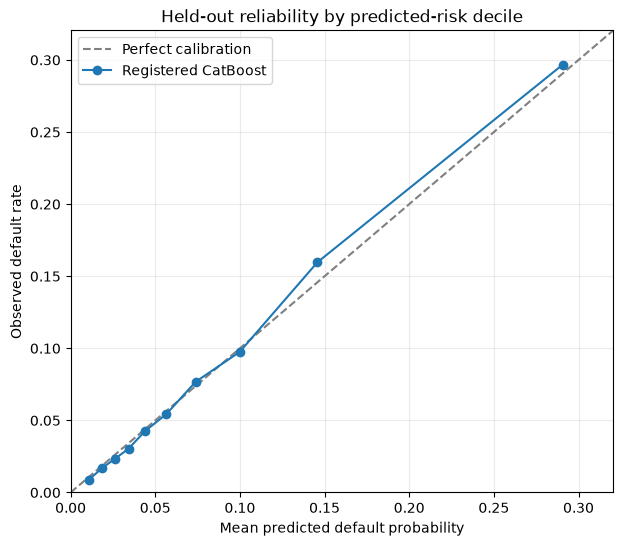

In [5]:
# Equal-count bins keep the high-risk end visible when most predictions are small.
calibration_df = pd.DataFrame({
    "predicted": test_prob,
    "observed": y_test.to_numpy(),
})
calibration_df["risk_bin"] = pd.qcut(
    calibration_df["predicted"].rank(method="first"),
    q=10,
    labels=False,
)
reliability = calibration_df.groupby("risk_bin", observed=True).agg(
    applicants=("observed", "size"),
    defaults=("observed", "sum"),
    mean_predicted=("predicted", "mean"),
    observed_default_rate=("observed", "mean"),
)
reliability.index = reliability.index + 1  # 1 = lowest predicted risk
reliability.index.name = "risk_decile_low_to_high"
display(reliability)

fig, ax = plt.subplots(figsize=(7, 6))
limit = max(reliability[["mean_predicted", "observed_default_rate"]].max()) * 1.08
ax.plot([0, limit], [0, limit], "--", color="gray", label="Perfect calibration")
ax.plot(
    reliability["mean_predicted"],
    reliability["observed_default_rate"],
    marker="o", label="Registered CatBoost",
)
ax.set(xlabel="Mean predicted default probability", ylabel="Observed default rate",
       title="Held-out reliability by predicted-risk decile", xlim=(0, limit), ylim=(0, limit))
ax.grid(alpha=0.25)
ax.legend()
plt.show()


A point above the diagonal means defaults occurred more often than predicted in that bin; below means the model overpredicted risk. Bins hide variation within each group. A weighted CatBoost fit may rank applicants well while its native probabilities are poorly calibrated.

## 2. Global explanations for the registered champion

CatBoost SHAP values attribute each prediction to features on the model's **raw log-odds** scale. We sample test rows to limit computation. The mean absolute value ranks the size of the contributions; it does not show their direction or prove causality.


,mean_absolute_shap_log_odds
EXT_SOURCE_2,0.293044
EXT_SOURCE_3,0.284570
EXT_SOURCE_1,0.164814
INSTALLMENT_LATE_PAYMENT_RATE,0.152841
CODE_GENDER,0.130666
CREDIT_TO_ANNUITY_RATIO,0.125736
GOODS_TO_CREDIT_RATIO,0.120050
EMPLOYMENT_YEARS,0.109681
AGE_YEARS,0.095307
AMT_ANNUITY,0.093446


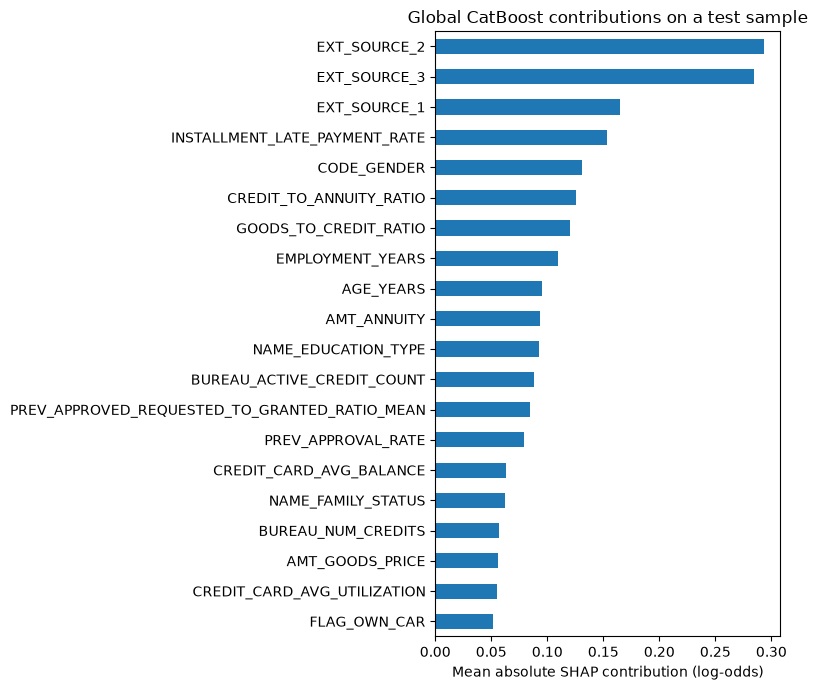

In [6]:
from catboost import Pool

rng = np.random.default_rng(42)
explain_positions = rng.choice(len(X_test), size=min(500, len(X_test)), replace=False)
X_explain = X_test.iloc[explain_positions].copy()
explain_pool = Pool(X_explain, cat_features=manifest["categorical_columns"])
shap_with_base = model.get_feature_importance(explain_pool, type="ShapValues")
if shap_with_base.shape != (len(X_explain), X_explain.shape[1] + 1):
    raise ValueError("Unexpected CatBoost SHAP output shape")
shap_values = shap_with_base[:, :-1]
base_values = shap_with_base[:, -1]

importance = pd.Series(
    np.abs(shap_values).mean(axis=0), index=X_explain.columns,
    name="mean_absolute_shap_log_odds",
).sort_values(ascending=False)
display(importance.head(25).to_frame())

fig, ax = plt.subplots(figsize=(8, 7))
importance.head(20).sort_values().plot.barh(ax=ax)
ax.set(xlabel="Mean absolute SHAP contribution (log-odds)",
       title="Global CatBoost contributions on a test sample")
plt.tight_layout()
plt.show()


/var/folders/sk/3z7vkbcj6m3640z6_9d52g040000gq/T/ipykernel_31618/3334277602.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


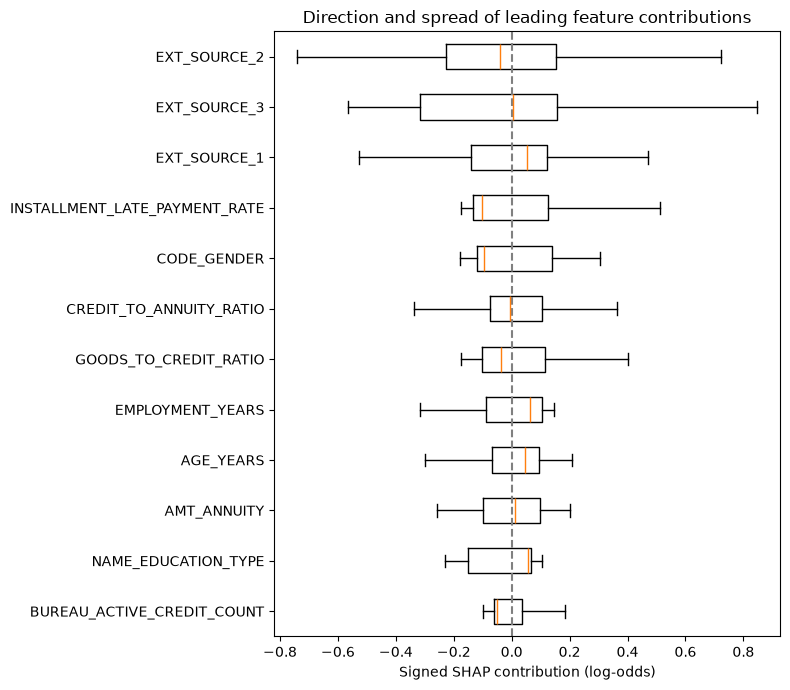

In [7]:
# Signed contributions show whether a feature pushed risk up or down for sampled rows.
top_features = importance.head(12).index.tolist()
feature_positions = [X_explain.columns.get_loc(name) for name in top_features]
fig, ax = plt.subplots(figsize=(8, 7))
ax.boxplot(
    [shap_values[:, pos] for pos in feature_positions],
    vert=False, tick_labels=top_features, showfliers=False,
)
ax.axvline(0, color="gray", linestyle="--")
ax.invert_yaxis()
ax.set(xlabel="Signed SHAP contribution (log-odds)",
       title="Direction and spread of leading feature contributions")
plt.tight_layout()
plt.show()


## 3. One applicant's explanation

Choose the highest predicted-risk applicant for a worked example. The SHAP baseline plus all feature contributions should equal the model's raw score. A positive contribution raises the predicted log-odds of default for this applicant; a negative one lowers it. Correlated features can share attribution, so individual values are model explanations rather than independent effects.


Applicant ID: 156227
Observed target (explanation only): 1
Predicted default probability: 91.47%
SHAP baseline log-odds: -2.8761
Raw score / SHAP reconstruction: 2.3724 2.3724


,feature,value,shap_log_odds,absolute_contribution
28,EXT_SOURCE_3,0.03711941259725027,1.486486,1.486486
27,EXT_SOURCE_2,1.1793951733999553e-05,1.437532,1.437532
44,BUREAU_ACTIVE_CREDIT_COUNT,9.0,0.689200,0.689200
13,DAYS_ID_PUBLISH,-79,0.310361,0.310361
26,EXT_SOURCE_1,NaN,0.163816,0.163816
42,NUM_DOCUMENTS,2.0,-0.158700,0.158700
47,PREV_APPROVED_GRANTED_AMT_SUM,0.0,0.157528,0.157528
10,NAME_HOUSING_TYPE,With parents,0.155619,0.155619
50,PREV_APPROVAL_RATE,NaN,0.147201,0.147201
58,GOODS_TO_CREDIT_RATIO,0.8256274768824307,0.133639,0.133639


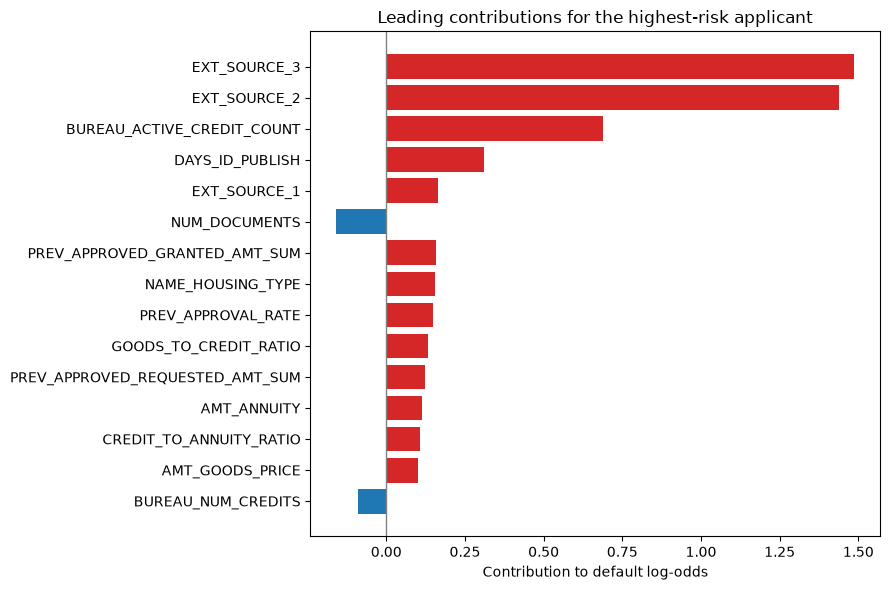

In [8]:
local_pos = int(np.argmax(test_prob))
X_local = X_test.iloc[[local_pos]]
local_pool = Pool(X_local, cat_features=manifest["categorical_columns"])
local_shap = model.get_feature_importance(local_pool, type="ShapValues")[0]
local_raw = float(np.asarray(model.predict(local_pool, prediction_type="RawFormulaVal")).item())
reconstructed_raw = float(local_shap.sum())
if not np.isclose(reconstructed_raw, local_raw, atol=1e-5):
    raise ValueError("SHAP values do not reconstruct the model raw score")

local_table = pd.DataFrame({
    "feature": X_local.columns,
    "value": X_local.iloc[0].astype(str).to_numpy(),
    "shap_log_odds": local_shap[:-1],
})
local_table["absolute_contribution"] = local_table["shap_log_odds"].abs()
local_table = local_table.sort_values("absolute_contribution", ascending=False)
print("Applicant ID:", test_df.iloc[local_pos][ID_COL])
print("Observed target (explanation only):", int(y_test.iloc[local_pos]))
print("Predicted default probability:", f"{test_prob[local_pos]:.2%}")
print("SHAP baseline log-odds:", round(float(local_shap[-1]), 4))
print("Raw score / SHAP reconstruction:", round(local_raw, 4), round(reconstructed_raw, 4))
display(local_table.head(20))

plot_local = local_table.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    plot_local["feature"], plot_local["shap_log_odds"],
    color=np.where(plot_local["shap_log_odds"] >= 0, "tab:red", "tab:blue"),
)
ax.axvline(0, color="gray", linewidth=1)
ax.set(xlabel="Contribution to default log-odds",
       title="Leading contributions for the highest-risk applicant")
plt.tight_layout()
plt.show()


In [9]:
from catboost import Pool

high_pos = int(np.argmax(test_prob))
low_pos = int(np.argmin(test_prob))

threshold = float(manifest["decision_threshold"])
near_pos = int(np.argmin(np.abs(test_prob - threshold)))

examples = {
    "highest risk": high_pos,
    "lowest risk": low_pos,
    "nearest threshold": near_pos,
}

rows = []

for label, pos in examples.items():
    applicant = X_test.iloc[[pos]]
    pool = Pool(
        applicant,
        cat_features=manifest["categorical_columns"],
    )
    contributions = model.get_feature_importance(
        pool, type="ShapValues"
    )[0, :-1]

    explanation = pd.DataFrame({
        "example": label,
        ID_COL: test_df.iloc[pos][ID_COL],
        "predicted_risk": test_prob[pos],
        "feature": applicant.columns,
        "value": applicant.iloc[0].astype(str).to_numpy(),
        "shap_log_odds": contributions,
    })

    rows.append(
        explanation.reindex(
            explanation["shap_log_odds"].abs()
            .sort_values(ascending=False)
            .index
        ).head(10)
    )

local_examples = pd.concat(rows, ignore_index=True)
display(local_examples)

,example,SK_ID_CURR,predicted_risk,feature,value,shap_log_odds
0,highest risk,156227,0.914698,EXT_SOURCE_3,0.03711941259725027,1.486486
1,highest risk,156227,0.914698,EXT_SOURCE_2,1.1793951733999553e-05,1.437532
2,highest risk,156227,0.914698,BUREAU_ACTIVE_CREDIT_COUNT,9.0,0.689200
3,highest risk,156227,0.914698,DAYS_ID_PUBLISH,-79,0.310361
4,highest risk,156227,0.914698,EXT_SOURCE_1,NaN,0.163816
5,highest risk,156227,0.914698,NUM_DOCUMENTS,2.0,-0.158700
6,highest risk,156227,0.914698,PREV_APPROVED_GRANTED_AMT_SUM,0.0,0.157528
7,highest risk,156227,0.914698,NAME_HOUSING_TYPE,With parents,0.155619
8,highest risk,156227,0.914698,PREV_APPROVAL_RATE,NaN,0.147201
9,highest risk,156227,0.914698,GOODS_TO_CREDIT_RATIO,0.8256274768824307,0.133639


EXT_SOURCE_3 missing in sample: 109 mean SHAP when missing: 0.05
EXT_SOURCE_2 missing in sample: 1 mean SHAP when missing: 0.311
EXT_SOURCE_1 missing in sample: 269 mean SHAP when missing: 0.095
NAME_HOUSING_TYPE missing in sample: 500 mean SHAP when missing: -0.0
PREV_APPROVAL_RATE missing in sample: 38 mean SHAP when missing: 0.122
GOODS_TO_CREDIT_RATIO missing in sample: 2 mean SHAP when missing: 0.352
AMT_GOODS_PRICE missing in sample: 2 mean SHAP when missing: -0.049
CREDIT_CARD_AVG_UTILIZATION missing in sample: 370 mean SHAP when missing: 0.035


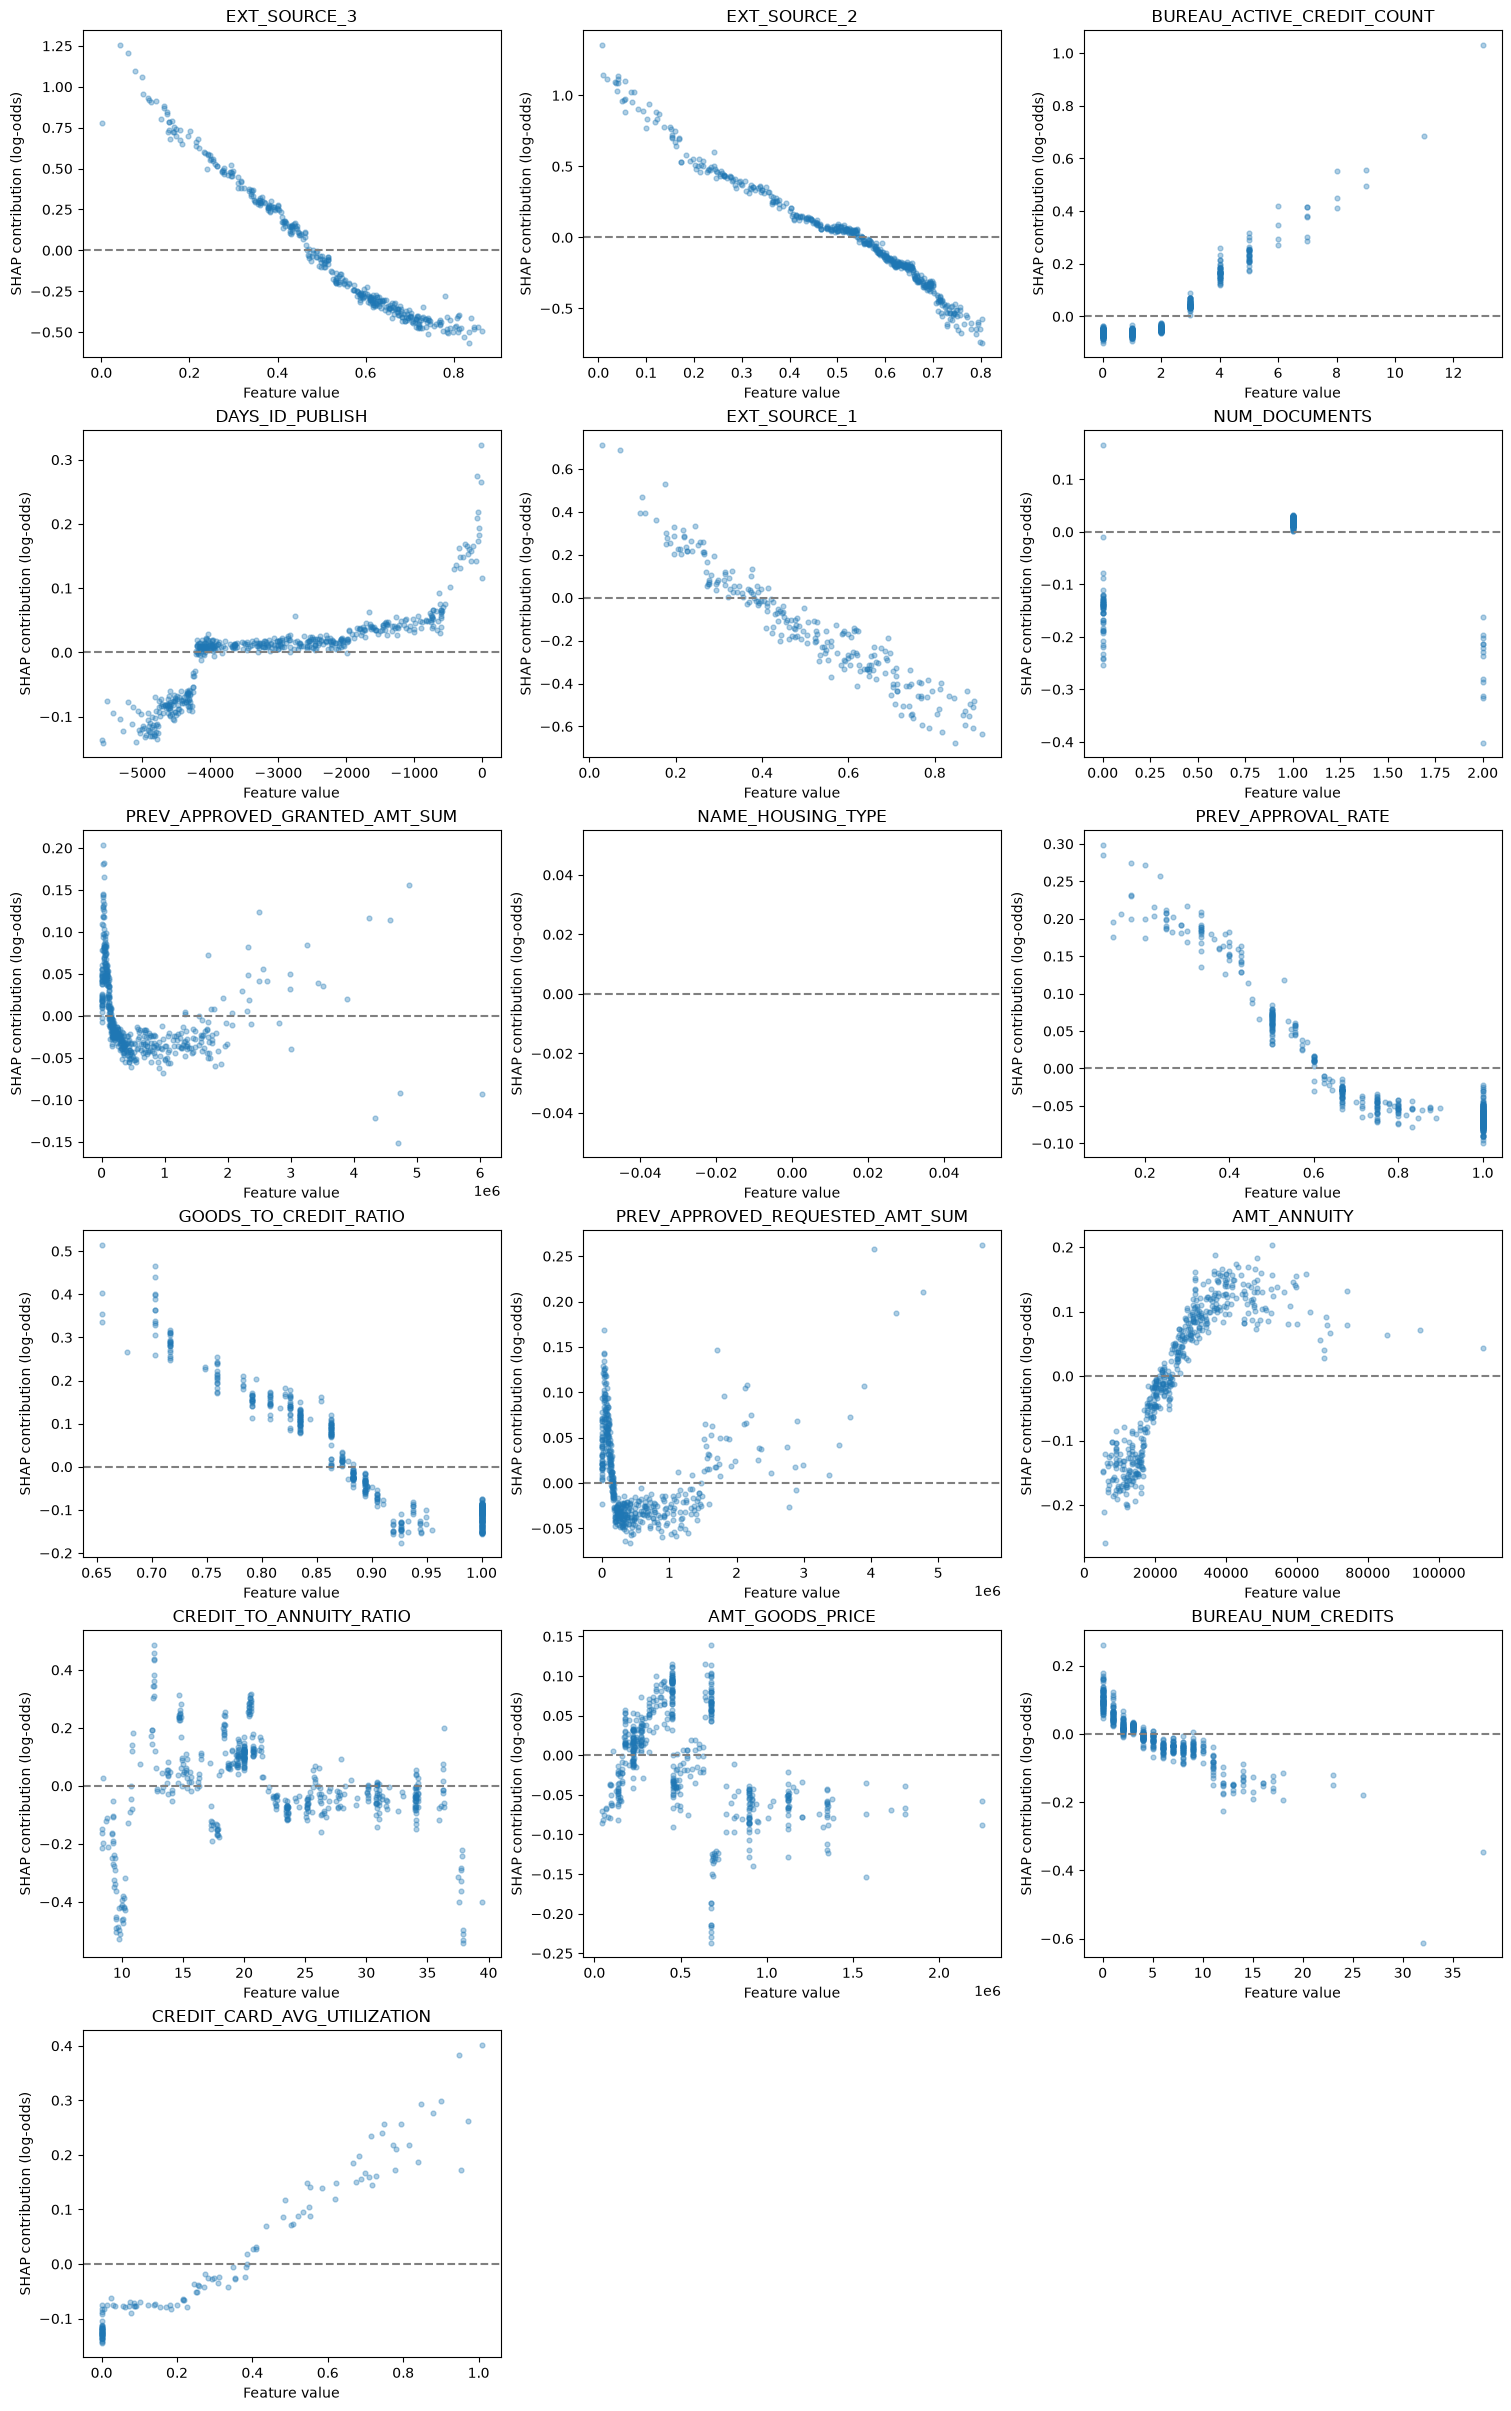

In [12]:
import math
import matplotlib.pyplot as plt
import pandas as pd

features_to_inspect = [
    'EXT_SOURCE_3',
    'EXT_SOURCE_2',
    'BUREAU_ACTIVE_CREDIT_COUNT',
    'DAYS_ID_PUBLISH',
    'EXT_SOURCE_1',
    'NUM_DOCUMENTS',
    'PREV_APPROVED_GRANTED_AMT_SUM',
    'NAME_HOUSING_TYPE',
    'PREV_APPROVAL_RATE',
    'GOODS_TO_CREDIT_RATIO',
    'PREV_APPROVED_REQUESTED_AMT_SUM',
    'AMT_ANNUITY',
    'CREDIT_TO_ANNUITY_RATIO',
    'AMT_GOODS_PRICE',
    'BUREAU_NUM_CREDITS',
    'CREDIT_CARD_AVG_UTILIZATION',
]

ncols = 3
nrows = math.ceil(len(features_to_inspect) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(15, nrows * 4),
    constrained_layout=True,
)
axes_flat = axes.flatten()

for ax, feature in zip(axes_flat, features_to_inspect):
  feature_pos = X_explain.columns.get_loc(feature)

  values = pd.to_numeric(X_explain[feature], errors="coerce")
  contributions = shap_values[:, feature_pos]
  present = values.notna().to_numpy()

  ax.scatter(
      values[present],
      contributions[present],
      s=12,
      alpha=0.35,
  )
  ax.axhline(0, color="gray", linestyle="--")
  ax.set(
      title=feature,
      xlabel="Feature value",
      ylabel="SHAP contribution (log-odds)",
  )

  missing_count = (~present).sum()
  if missing_count:
    print(
        feature,
        "missing in sample:",
        missing_count,
        "mean SHAP when missing:",
        round(contributions[~present].mean(), 3),
    )

# Hide any empty subplots in the last row
for ax in axes_flat[len(features_to_inspect) :]:
  ax.set_visible(False)

plt.show()

#### Save Model report

In [13]:
import importlib.metadata as metadata
import subprocess
from datetime import datetime, timezone
from pathlib import Path

import mlflow
from mlflow import MlflowClient

from credit_default_risk.config import PROJECT_ROOT

MODEL_NAME = "credit-default-risk-catboost"
MODEL_ALIAS = "champion"

mlflow.set_tracking_uri(TRACKING_URI)
client = MlflowClient()
version = client.get_model_version_by_alias(MODEL_NAME, MODEL_ALIAS)

def git_revision():
    result = subprocess.run(
        ["git", "rev-parse", "HEAD"],
        cwd=PROJECT_ROOT,
        capture_output=True,
        text=True,
        check=False,
    )
    return result.stdout.strip() if result.returncode == 0 else None

inference_contract = {
    "registered_model_name": MODEL_NAME,
    "registered_model_version": str(version.version),
    "registered_model_run_id": version.run_id,
    "feature_columns": manifest["feature_columns"],
    "categorical_columns": manifest["categorical_columns"],
    "prepared_feature_dtypes": {
        col: str(dtype) for col, dtype in X_test.dtypes.items()
    },
    "missing_values": {
        "categorical": "__MISSING__",
        "numeric": "NaN; passed to CatBoost",
    },
    "positive_class": 1,
    "probability_output": "predict_proba(X)[:, 1]",
    "decision_threshold": float(manifest["decision_threshold"]),
    "threshold_policy": manifest["threshold_policy"],
    "preprocessing_git_revision": git_revision(),
    "package_versions": {
        name: metadata.version(name)
        for name in ["catboost", "pandas", "numpy", "scikit-learn", "mlflow"]
    },
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
}

assert list(inference_contract["prepared_feature_dtypes"]) == (
    inference_contract["feature_columns"]
)

display(pd.Series({
    "model": MODEL_NAME,
    "version": version.version,
    "features": len(inference_contract["feature_columns"]),
    "threshold": inference_contract["decision_threshold"],
    "preprocessing_revision": inference_contract["preprocessing_git_revision"],
}))

model                                 credit-default-risk-catboost
version                                                          1
features                                                        60
threshold                                                 0.184522
preprocessing_revision    d04cf296b97564feb296728f6304e6bf065011cd
dtype: object

In [14]:
from catboost import CatBoostClassifier

local_model_path = PROJECT_ROOT / "artifacts" / "catboost_final" / "model.cbm"

local_model = CatBoostClassifier()
local_model.load_model(str(local_model_path))

batch = X_test.head(20)
assert batch.columns.tolist() == inference_contract["feature_columns"]
assert {
    col: str(dtype) for col, dtype in batch.dtypes.items()
} == inference_contract["prepared_feature_dtypes"]

local_prob = local_model.predict_proba(batch)[:, 1]
registered_prob = model.predict_proba(batch)[:, 1]

np.testing.assert_allclose(
    local_prob,
    registered_prob,
    rtol=1e-7,
    atol=1e-8,
)

print("Local and registered predictions match for", len(batch), "rows.")

Local and registered predictions match for 20 rows.


In [15]:
import json

report_dir = (
    PROJECT_ROOT
    / "reports"
    / "final_model"
    / f"{MODEL_NAME}-v{version.version}"
)
report_dir.mkdir(parents=True, exist_ok=True)

report = {
    "model_name": MODEL_NAME,
    "model_version": str(version.version),
    "model_run_id": version.run_id,
    "evaluation_split": "held-out test",
    "metrics": {
        key: float(value) if isinstance(value, (int, float, np.number)) else value
        for key, value in metrics.items()
    },
    "calibration_decision": (
        "Sigmoid calibration was investigated on development data "
        "and was not adopted for this registered model."
    ),
    "decision_threshold_source": manifest["threshold_policy"],
}

(report_dir / "evaluation.json").write_text(
    json.dumps(report, indent=2),
    encoding="utf-8",
)
(report_dir / "inference_contract.json").write_text(
    json.dumps(inference_contract, indent=2),
    encoding="utf-8",
)
reliability.to_csv(report_dir / "calibration_deciles.csv")

# Recreate the existing reliability plot as a standalone report artifact.
fig, ax = plt.subplots(figsize=(7, 6))
limit = 1.08 * max(
    reliability["mean_predicted"].max(),
    reliability["observed_default_rate"].max(),
)
ax.plot([0, limit], [0, limit], "--", color="gray",
        label="Perfect calibration")
ax.plot(
    reliability["mean_predicted"],
    reliability["observed_default_rate"],
    marker="o",
    label="Registered CatBoost",
)
ax.set(
    xlabel="Mean predicted default probability",
    ylabel="Observed default rate",
    title=f"Calibration: {MODEL_NAME} v{version.version}",
    xlim=(0, limit),
    ylim=(0, limit),
)
ax.legend()
ax.grid(alpha=0.25)
fig.savefig(report_dir / "calibration.png", dpi=160, bbox_inches="tight")
plt.close(fig)

print("Report saved to:", report_dir)

Report saved to: /Users/abdelhakimosama/Projects/Credit_Default_Risk/reports/final_model/credit-default-risk-catboost-v1
